In [5]:
import pandas as pd
import numpy as np
import librosa
import os
import matplotlib.pyplot as plt

In [6]:
metas = pd.read_csv('data/schematics-2026/train/metadata.csv')
metas

,file_id,audio_path,label,source_group
0,313fef340a5c0be86a6c3ec29bb0fc5b684accd321f994...,train/audio/313fef340a5c0be86a6c3ec29bb0fc5b68...,Bondol Jawa,d20bbb9d3f16cea2e0988846afe752fa7233d9de8cffd7...
1,9f0d58ab5eb8bdad788915ba9053c9a23b2709461ee290...,train/audio/9f0d58ab5eb8bdad788915ba9053c9a23b...,Bondol Jawa,100f6ca56523c6b10f0da48fca4a3100f7e2fad1a2c238...
2,f18d5438129a6c8fabe09f8d108c44b0fa40880cf0ffcb...,train/audio/f18d5438129a6c8fabe09f8d108c44b0fa...,Kutilang,81b28e5fe98ace507d968e64f7cf87d7c4af112b8d3d19...
3,ec4ea61e4451227b2ee1e4046296b515e4f58761ea4097...,train/audio/ec4ea61e4451227b2ee1e4046296b515e4...,Bondol Jawa,d20bbb9d3f16cea2e0988846afe752fa7233d9de8cffd7...
4,d0bd6e1839642188508060a7bb5c29c1a8251ada1a48f0...,train/audio/d0bd6e1839642188508060a7bb5c29c1a8...,Kutilang,0d9c30be6d4b5d92c8384b9e5fd3cf908e4b8a965c68a9...
...,...,...,...,...
1821,aa83eca4af347ade7cedd5409c06b8878c062e94b4adc9...,train/audio/aa83eca4af347ade7cedd5409c06b8878c...,Bondol Jawa,d20bbb9d3f16cea2e0988846afe752fa7233d9de8cffd7...
1822,7212eee35423e64bdcec85d1418d5d68a6ca11fc45d2fb...,train/audio/7212eee35423e64bdcec85d1418d5d68a6...,Kutilang,81b28e5fe98ace507d968e64f7cf87d7c4af112b8d3d19...
1823,18a6da4c3e45e6a6cf3f3c51c99b5028902663d537490a...,train/audio/18a6da4c3e45e6a6cf3f3c51c99b502890...,Bondol Jawa,c04cd5b92abf641020d05d3c6493551c25788d00c0cf3d...
1824,bff6da68be0e6f57c7962d267f1854a54b3fba3ab75cbf...,train/audio/bff6da68be0e6f57c7962d267f1854a54b...,Bondol Jawa,90eace95f77b860fc6f9a3ec8c870c251172f7292ca8f6...


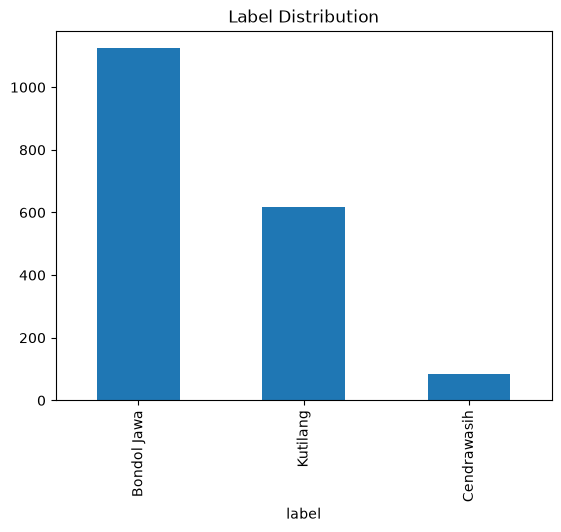

In [7]:
metas['label'].value_counts().plot(kind='bar', title='Label Distribution')
plt.show()

In [8]:
metas.info()

<class 'pandas.DataFrame'>
RangeIndex: 1826 entries, 0 to 1825
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   file_id       1826 non-null   str  
 1   audio_path    1826 non-null   str  
 2   label         1826 non-null   str  
 3   source_group  1826 non-null   str  
dtypes: str(4)
memory usage: 447.7 KB


In [10]:
print(metas.groupby('label')['source_group'].nunique())
metas.groupby(['label', 'source_group']).size()

label
Bondol Jawa    7
Cendrawasih    4
Kutilang       4
Name: source_group, dtype: int64


label        source_group                                                    
Bondol Jawa  100f6ca56523c6b10f0da48fca4a3100f7e2fad1a2c2389e1c7964a1e3e19cf9    117
             347254a6f705ce7e515383d02a1c3c81a22ef79a9a2b748e9224327b1a85bbf5     82
             6b857072c74b632b612a73635492716c88e84caf65733651c4b79615b56771c7    232
             90eace95f77b860fc6f9a3ec8c870c251172f7292ca8f6a3748c8d1355549406    123
             c04cd5b92abf641020d05d3c6493551c25788d00c0cf3d20fb547bb5a2218c9b    176
             d20bbb9d3f16cea2e0988846afe752fa7233d9de8cffd7b978a1c8096c6a89eb    336
             feb85101266cbc746f76b5403257002d8bd4f5b73d4375a0acd6029e132df6ab     58
Cendrawasih  660c17c0976771310b2cc8ff4db25c3c0638ec870c6a328ea6be82e1b1dbeedb     16
             6895fb85e751062fc362a12424f238cdb6ed5164c09df37e3d0323cff46de107     29
             8a3900e65b5389d260970ab05a5415cbbd4a4548cf0e3f9051f786463c0f7ef3     35
             d7bc3d5bed71ea4c9ab146301ba34f872cb0c68e681ff3cb23328687db1

In [12]:
from sklearn.model_selection import StratifiedGroupKFold
sgkf = StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=42)
for k, (tr, va) in enumerate(sgkf.split(metas, metas['label'], groups=metas['source_group'])):
    print(k, metas.iloc[va]['label'].value_counts().to_dict())

0 {'Bondol Jawa': 336, 'Kutilang': 132, 'Cendrawasih': 3}
1 {'Bondol Jawa': 290, 'Kutilang': 143, 'Cendrawasih': 16}
2 {'Bondol Jawa': 240, 'Kutilang': 178, 'Cendrawasih': 35}
3 {'Bondol Jawa': 258, 'Kutilang': 166, 'Cendrawasih': 29}
